# Imaging Phenotype Variants Analyses

In [1]:
import sys
import seaborn as sns
import numpy as np
import polars as pl
from tqdm import tqdm
import matplotlib as mpl
import matplotlib.pyplot as plt
from pycytominer.feature_select import feature_select
from sklearn.decomposition import PCA
import pandas as pd
from matplotlib.patches import Patch
from dynamicTreeCut import cutreeHybrid
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
import matplotlib.font_manager as fm
from scipy.spatial.distance import pdist
# from utils import inverse_normal_transform
# from adjustText import adjust_text
# from sklearn.metrics import silhouette_score
# from matplotlib.colors import ListedColormap
# from matplotlib.ticker import FixedFormatter

# Force TrueType font embedding (Type 42)
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

font_path = "../../../../1_allele_collection/4_manuscript_figures/ARIAL.TTF"
fm.fontManager.addfont(font_path)

font_prop = fm.FontProperties(fname=font_path)
# Set font family to one of the accepted fonts
plt.rcParams.update({
    "font.family": font_prop.get_name(),
    "font.sans-serif": ["ARIAL"],
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})
sns.set_theme(style='white')

# Verify settings
# print(f"pdf.fonttype: {mpl.rcParams['pdf.fonttype']}")
# print(f"ps.fonttype: {mpl.rcParams['ps.fonttype']}")
# print(f"font.family: {mpl.rcParams['font.family']}")

sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../../..")
from analyses_plot_utils import *

FEATURE_IMPORTANCE_THRES = 0.01
SIGNALING_DOMAINS = [
    "g2p_Signal (UniProt)",
    "g2p_Transit peptide (UniProt)",
    "g2p_Transmembrane (UniProt)",
    "g2p_Topological domain (UniProt)",
    "g2p_Intramembrane (UniProt)",
    "g2p_Lipidation (UniProt)"
]
META_COLS = [
    "gene_variant",
    "Metadata_Bio_Batch",
    "img_pheno_score",
    "img_misloc_score",
    "img_pheno_hit",
    "img_misloc_hit",
    "clinvar_clnsig_clean",
    "clinvar_clnsig_clean_pp_strict",
    "clinvar_OMIM_id",
    "OMIM_IDs",
    "OMIM_disease_names",
    "disease_modules",
    "inheritance_pattern",
    "plddt_f32",
    "rsa_f32", 
    "pLDDT_Category",
    "RSA_Category",
] + SIGNALING_DOMAINS

In [18]:
imaging_summary_clinvar.filter(
    pl.col("Gene")=="PLP1"
)

Gene,gene_variant,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_orig_pval,U2OS_prot_abun_t_adj_pval,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP_ADJ,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP_ADJ,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP_ADJ,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep1_GFP_ADJ,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,…,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,img_pheno_score,img_misloc_score,img_pheno_hit,img_misloc_hit,img_pheno_hit_strict
str,str,f64,f64,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,str,str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str,bool,f64,f64,bool,bool,bool
"""PLP1""","""PLP1_Thr147Pro""",-0.705846,0.506751,-1.52601,0.177857,0.220251,0.220251,"""2024_01_Batch_7-8""",true,true,false,false,false,false,true,true,false,false,false,false,0.994112,0.993713,0.554743,0.662553,0.610156,0.586708,0.595633,0.514452,0.643864,0.568457,0.989611,0.992722,0.577783,0.70586,0.681243,0.54103,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,90.83,33.802814,""">90""","""10-90""","""312080""","""x-linked recessive""","""OMIM""","""Rare genetic eye disease; Rare…",2,"""PELIZAEUS-MERZBACHER DISEASE""",false,0.993713,0.994112,true,true,true
"""PLP1""","""PLP1_Pro181Ser""",0.808239,0.449803,1.251617,0.257294,0.30648,0.30648,"""2024_01_Batch_7-8""",false,false,false,false,false,false,false,false,false,false,false,false,0.89712,0.916835,0.673774,0.577555,0.497455,0.683775,0.716605,0.450942,0.594032,0.707601,0.931737,0.882555,0.650944,0.543968,0.561078,0.639947,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,81.33,41.911766,"""70-90""","""10-90""","""312080""","""x-linked recessive""","""OMIM""","""Rare genetic eye disease; Rare…",2,"""PELIZAEUS-MERZBACHER DISEASE""",false,0.916835,0.89712,false,false,false
"""PLP1""","""PLP1_Asp168His""",1.3441,0.227508,-0.692488,0.514524,0.569476,0.569476,"""2024_01_Batch_7-8""",false,true,false,false,false,false,false,false,false,false,false,false,0.943773,0.944473,0.442162,0.514047,0.517478,0.442843,0.460465,0.426125,0.48168,0.472265,0.945148,0.933509,0.425221,0.60883,0.546415,0.412058,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,89.16,14.11043,"""70-90""","""10-90""","""312080""","""x-linked recessive""","""OMIM""","""Rare genetic eye disease; Rare…",2,"""PELIZAEUS-MERZBACHER DISEASE""",false,0.944473,0.943773,true,false,false
"""PLP1""","""PLP1_Gly186Cys""",-0.678672,0.522647,2.408311,0.052695,0.074968,0.074968,"""2024_0

## 1. Loading data

In [16]:
ref_var_cell_all_prof_df = pl.read_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc.parquet")
feat_df = pl.read_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")

In [17]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col("img_pheno_hit"),
)
pheno_alleles = imaging_summary_clinvar_hits["gene_variant"].to_list()
print("Imaging phenotype alleles:", len(pheno_alleles))

## Protein abundance change
imaging_summary_clinvar_abund_chg = imaging_summary_clinvar.filter(
    (pl.col("U2OS_prot_abun_t_stat").is_not_null()) & (pl.col("U2OS_prot_abun_t_pval") < 0.05/943)
)
prot_abund_chg_alleles = imaging_summary_clinvar_abund_chg["gene_variant"].to_list()

# ax = sns.regplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     y="AUROC_Mean_GFP_ADJ"
# )
# ax.set_xlim(0.45, 1.05)
# ax.set_ylim(0.45, 1.05)
# plt.show()

# ax = sns.regplot(
#     data=imaging_summary_clinvar.filter(
#         (pl.col("AUROC_Mean_GFP")>.9) | (pl.col("AUROC_Mean_GFP_ADJ")>.9)
#     ).to_pandas(),
#     x="AUROC_Mean_GFP",
#     y="AUROC_Mean_GFP_ADJ"
# )
# ax.set_xlim(0.825, 1.005)
# ax.set_ylim(0.825, 1.005)
# plt.show()
imaging_summary_clinvar_hits

Imaging phenotype alleles: 140


Gene,gene_variant,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_orig_pval,U2OS_prot_abun_t_adj_pval,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP_ADJ,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP_ADJ,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP_ADJ,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep1_GFP_ADJ,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,…,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,img_pheno_score,img_misloc_score,img_pheno_hit,img_misloc_hit,img_pheno_hit_strict
str,str,f64,f64,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,str,str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str,bool,f64,f64,bool,bool,bool
"""PMP22""","""PMP22_Leu16Pro""",2.879899,0.028061,-7.896223,0.000219,0.000773,0.000773,"""2024_01_Batch_7-8""",true,true,false,false,false,false,false,false,false,false,false,false,0.972047,0.978439,0.527243,0.689174,0.720481,0.593552,0.678036,0.737426,0.740387,0.617828,0.990193,0.986164,0.509068,0.703537,0.637962,0.436657,…,null,null,-42.5,null,null,null,null,null,"""H (helix)""","""H (α-helix)""",null,null,null,null,null,null,null,null,"""Helical""",null,null,98.0,14.634146,""">90""","""10-90""","""118220""","""autosomal dominant""","""OMIM""","""Genetic otorhinolaryngologic d…",3,"""CHARCOT-MARIE-TOOTH DISEASE, D…",false,0.978439,0.972047,true,true,false
"""FXN""","""FXN_Met1Ile""",3.750084,0.007167,-4.062661,0.004793,0.009382,0.009382,"""2024_01_Batch_7-8""",true,true,false,false,false,false,true,true,false,false,false,false,0.989749,0.996017,0.789821,0.868702,0.745553,0.809808,0.771908,0.687244,0.870907,0.746232,0.997118,0.989749,0.847707,0.803862,0.866496,0.83341,…,null,null,80.4,null,null,null,null,null,"""C (loop/coil)""","""C (loop/coil)""",null,null,null,null,null,null,null,"""Mitochondrion""",null,null,null,45.27,100.0,"""$\leqslant$50""","""$\geqslant$90""","""229300""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",3,"""FRIEDREICH ATAXIA""",false,0.996017,0.989749,true,true,true
"""SFTPC""","""SFTPC_Ile73Thr""",-1.5761,0.166074,18.02773,0.000002,0.000028,0.000028,"""2024_01_Batch_7-8""",true,true,false,false,false,false,true,true,false,false,false,false,0.994773,0.994331,0.825766,0.822123,0.807482,0.850061,0.968498,0.816135,0.952122,0.936955,0.994104,0.994773,0.731623,0.798829,0.692124,0.714576,…,null,"""Propeptide""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,50.61,82.84023,"""50-70""","""10-90""","""610913""","""autosomal dominant""","""OMIM""","""Rare genetic respiratory disea…",1,"""SURFACTANT METABOLISM DYSFUNCT…",false,0.994331,0.994773,true,true,true
"""ML

## 2. Imaging Phenotype Variants

In [5]:
# TOP_NUM_FEAT_MISLOC_VAR = 5
# # Get top 10 for each variant with feature names
# top_feat_misloc_alleles = []
# for col in misloc_alleles:
#     top_feats = feat_df.filter(
#         pl.col(col).is_in(pl.col(col).top_k(TOP_NUM_FEAT_MISLOC_VAR))
#     ).select(["cp_feature", col])
#     # print(top_feats.sort(col))
#     top_feat_misloc_alleles.append(top_feats)
    
# # Start with all features and left join each variant's top 10
# result_df = feat_df.select("cp_feature").unique().sort("cp_feature")
# for i, col in enumerate(misloc_alleles):
#     result_df = result_df.join(top_feat_misloc_alleles[i], on="cp_feature", how="left")

# misloc_var_top10_feat_df = result_df.select(
#     ["cp_feature"] + pheno_alleles
# ).filter(
#     ~pl.all_horizontal(pl.all().exclude("cp_feature").is_null())
# )
# get_top_n_feats_misloc_alleles = misloc_var_top10_feat_df["cp_feature"].to_list()
# len(get_top_n_feats_misloc_alleles)

In [6]:
pheno_var_sig_feat_df = feat_df.filter(
    # pl.col(col).is_in(pl.col(col).top_k(TOP_NUM_FEAT_MISLOC_VAR))
    pl.max_horizontal(pheno_alleles) > FEATURE_IMPORTANCE_THRES
)
get_sig_feats_pheno_alleles = pheno_var_sig_feat_df["cp_feature"].to_list()

### 2.1 Calculate Z-score for phenotypic directional change

In [7]:
norm_vars_feat_df, norm_var_sc_feat_df = pl.DataFrame(), pl.DataFrame()
sig_diff_feat = [feat for feat in get_sig_feats_pheno_alleles if feat in ref_var_cell_all_prof_df.columns] #[feat for feat in get_top_feats if feat in ref_var_cell_all_prof_df.columns]

for gene in tqdm(imaging_summary_clinvar_hits["Gene"].unique().to_list()):
    gene_mean = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).mean().to_numpy()[0].tolist()
    gene_std = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).std().to_numpy()[0].tolist()

    # print(gene, np.mean(gene_mean), np.min(gene_std))
    z_norm_var_sc_feat_df = ref_var_cell_all_prof_df.filter(
        (pl.col("Metadata_gene_allele").str.starts_with(f"{gene}_"))
        &(pl.col("Metadata_gene_allele")!=gene)
        &(pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_hits["gene_variant"].unique()))
    ).with_columns(
        [((pl.col(col) - pl.lit(gene_mean[i])) / pl.lit(gene_std[i])).alias(col)
        for i, col in enumerate(sig_diff_feat)]
    )
    norm_var_sc_feat_df = pl.concat([
        norm_var_sc_feat_df,
        z_norm_var_sc_feat_df
    ])
    z_norm_var_feat_df = z_norm_var_sc_feat_df.group_by(
        "Metadata_gene_allele", "Metadata_Plate", "Metadata_Well" ## aggregate by well first
    ).agg(
        pl.col(col).median().alias(col)
        for col in sig_diff_feat
    ).group_by(
        "Metadata_gene_allele" ## aggregate by allele
    ).agg(
        pl.col(col).median().alias(col)
        for col in sig_diff_feat
    )#.to_pandas().set_index("Metadata_gene_allele")[sig_diff_feat]

    norm_vars_feat_df = pl.concat(
        [norm_vars_feat_df, z_norm_var_feat_df],
         how="diagonal"
    )

100%|██████████| 44/44 [00:09<00:00,  4.49it/s]


### 2.2 Feature selection

In [8]:
## This is already a Z-scored feature matrix, no extra processing is needed
var_zscore_feat_gfp_filtered_int_df = norm_vars_feat_df.to_pandas()#.set_index("Metadata_gene_allele")

# 2. Apply Winsorization (Clipping). NOT NEEDED
# We clip values at -5 (lower) and +5 (upper)
# var_zscore_feat_gfp_filtered_int_df = var_zscore_feat_gfp_filtered_int_df.clip(lower=-5, upper=5).reset_index()

## feature selection
var_zscore_feat_gfp_filtered_int_feat_sel_df = feature_select(
    var_zscore_feat_gfp_filtered_int_df, operation="variance_threshold"
)
var_zscore_feat_gfp_filtered_int_feat_sel_df = pl.DataFrame(
    feature_select(var_zscore_feat_gfp_filtered_int_feat_sel_df, operation="correlation_threshold")
)

## Append important medadata to data frame
var_zscore_feat_gfp_filtered_int_feat_sel_df = var_zscore_feat_gfp_filtered_int_feat_sel_df.join(
    imaging_summary_clinvar.select(META_COLS).rename(
        {k: f"Metadata_{k}" for k in META_COLS if "Metadata" not in k}
    ),
    left_on="Metadata_gene_allele",
    right_on="Metadata_gene_variant",
    how="inner"
)

df_meta = var_zscore_feat_gfp_filtered_int_feat_sel_df.to_pandas().set_index("Metadata_gene_allele")
df = df_meta[[c for c in df_meta.columns if "Metadata_" not in c]]
metadata_cols = [c for c in df_meta.columns if "Metadata_" in c]

### 2.3 Dimension reduction and clustering

In [9]:
# ----------------------------------------------------------------------
# 1. Robust PCA
# ----------------------------------------------------------------------
# Dynamic component selection: Keep 90% of variance
pca = PCA(n_components=0.90, random_state=42)
data_pca = pca.fit_transform(df)
n_pcs = data_pca.shape[1]
print(f"PCA retained {n_pcs} components explaining 90% variance.")

# Create PCA DataFrame dynamically
pca_cols = [f"PC{i+1}" for i in range(n_pcs)]
pca_df = pd.DataFrame(data_pca, columns=pca_cols)
# Safely attach metadata using index alignment
pca_df = pd.concat([df_meta[metadata_cols].reset_index(drop=True), pca_df], axis=1)

PCA retained 9 components explaining 90% variance.


Minimum cluster size: 7
..cutHeight not given, setting it to 38.62226667512973  ===>  99% of the (truncated) height range in dendro.
..done.


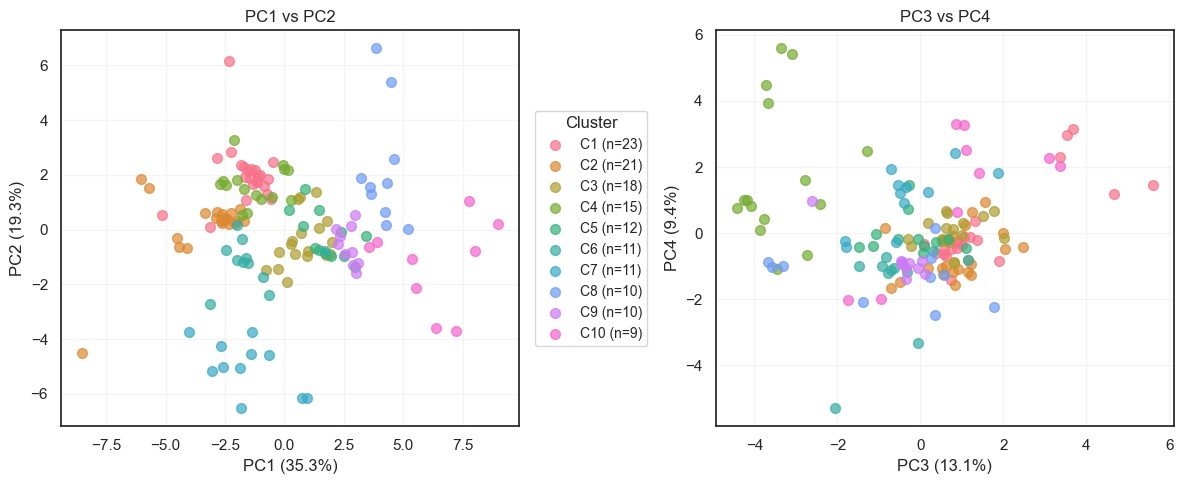

In [10]:
# ----------------------------------------------------------------------
# 2. Hierarchical Clustering on PCA
# ----------------------------------------------------------------------
Z = linkage(data_pca, method='ward', metric='euclidean')
dist_matrix = pdist(data_pca, metric='euclidean')
linkage_matrix_pca = linkage(data_pca, method='ward', optimal_ordering=True)

# Dynamic tree cut - adapts to tree structure with minimum cluster size
# minClusterSize: minimum number of samples per cluster (key parameter)
min_cluster_size = max(5, len(data_pca) // 20)
print(f"Minimum cluster size: {min_cluster_size}")

cluster_labels = cutreeHybrid(
    Z,
    dist_matrix,
    minClusterSize=min_cluster_size,
    deepSplit=2,
)["labels"]

n_clusters = len(set(cluster_labels))
colors = sns.color_palette("husl", n_clusters)
unique_labels = sorted(np.unique(cluster_labels))
color_map = {label: colors[i] for i, label in enumerate(unique_labels)}

# ----------------------------------------------------------------------
# 3. Plot 1: PCA Scatter (PC1/PC2 and PC3/PC4)
# ----------------------------------------------------------------------
n_pcs = data_pca.shape[1]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# PC1 vs PC2
for c in unique_labels:
    mask = cluster_labels == c
    axes[0].scatter(
        data_pca[mask, 0], 
        data_pca[mask, 1],
        c=[color_map[c]], 
        label=f'C{c} (n={mask.sum()})',
        alpha=0.7,
        s=50
    )
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[0].set_title('PC1 vs PC2')
axes[0].legend(bbox_to_anchor=(1.02, 0.5), loc='center left', fontsize=10, title="Cluster")
axes[0].grid(alpha=0.2)

# PC3 vs PC4
if n_pcs >= 4:
    for c in unique_labels:
        mask = cluster_labels == c
        axes[1].scatter(
            data_pca[mask, 2], 
            data_pca[mask, 3],
            c=[color_map[c]], 
            label=f'C{c} (n={mask.sum()})',
            alpha=0.7,
            s=50
        )
    axes[1].set_xlabel(f'PC3 ({pca.explained_variance_ratio_[2]:.1%})')
    axes[1].set_ylabel(f'PC4 ({pca.explained_variance_ratio_[3]:.1%})')
    axes[1].set_title('PC3 vs PC4')
    axes[1].grid(alpha=0.2)
else:
    axes[1].text(0.5, 0.5, f'Only {n_pcs} PCs available', ha='center', va='center')
    axes[1].set_title('PC3 vs PC4 (unavailable)')

plt.tight_layout()
plt.show()

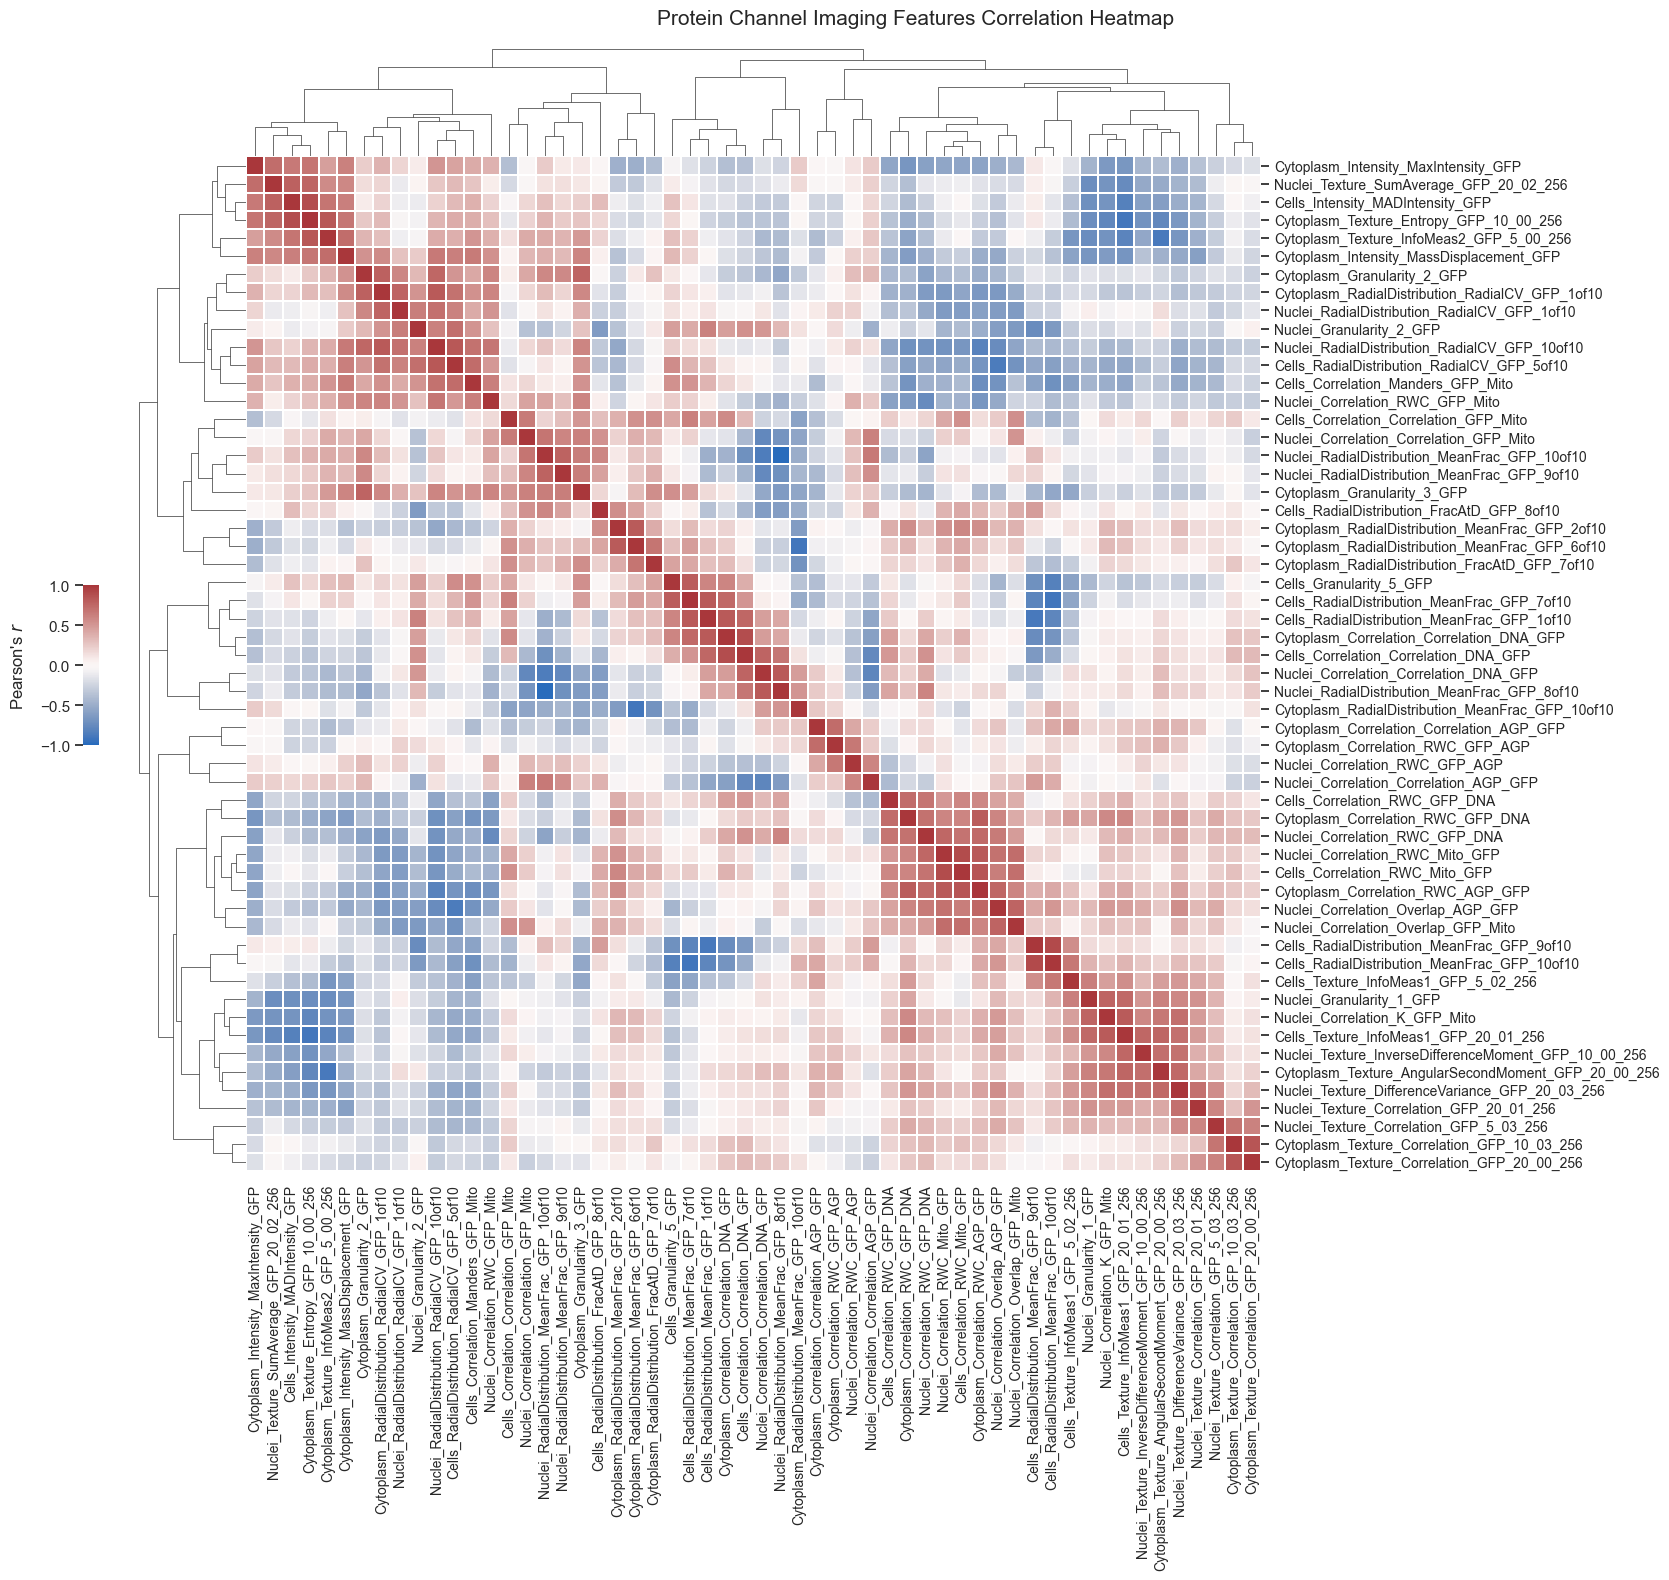

In [11]:
# Correlation clustermap (run first to get column linkage)
# Correlation clustermap with optimal leaf ordering
corr_df = df.corr()

# Convert correlation to distance (1 - r), then to condensed form
corr_dist = 1 - corr_df.values
np.fill_diagonal(corr_dist, 0)  # Ensure diagonal is 0
corr_dist_condensed = squareform(corr_dist)

# Compute linkage with optimal ordering
col_linkage = linkage(corr_dist_condensed, method='average', optimal_ordering=True)

g_corr = sns.clustermap(
    data=corr_df,
    cmap="vlag", vmin=-1,
    row_linkage=col_linkage,
    col_linkage=col_linkage,
    cbar_pos=(-.02, 0.55, 0.01, 0.1),
    yticklabels=1, xticklabels=1,
    # square=True,
    figsize=(16, 16),
    linewidth=.05,
    dendrogram_ratio=(0.1, 0.1),
    
)
g_corr.fig.suptitle("Protein Channel Imaging Features Correlation Heatmap", fontsize=15, y=1.01)
g_corr.cax.yaxis.set_label_position('left')
g_corr.cax.yaxis.set_ticks_position('left')
g_corr.cax.set_ylabel(r"Pearson's $r$", labelpad=10)
g_corr.ax_heatmap.set_xticklabels(g_corr.ax_heatmap.get_xticklabels(), fontsize=10)
g_corr.ax_heatmap.set_yticklabels(g_corr.ax_heatmap.get_yticklabels(), fontsize=10)
plt.show()

# Extract column linkage and order
col_order = list(corr_df.columns[g_corr.dendrogram_col.reordered_ind])

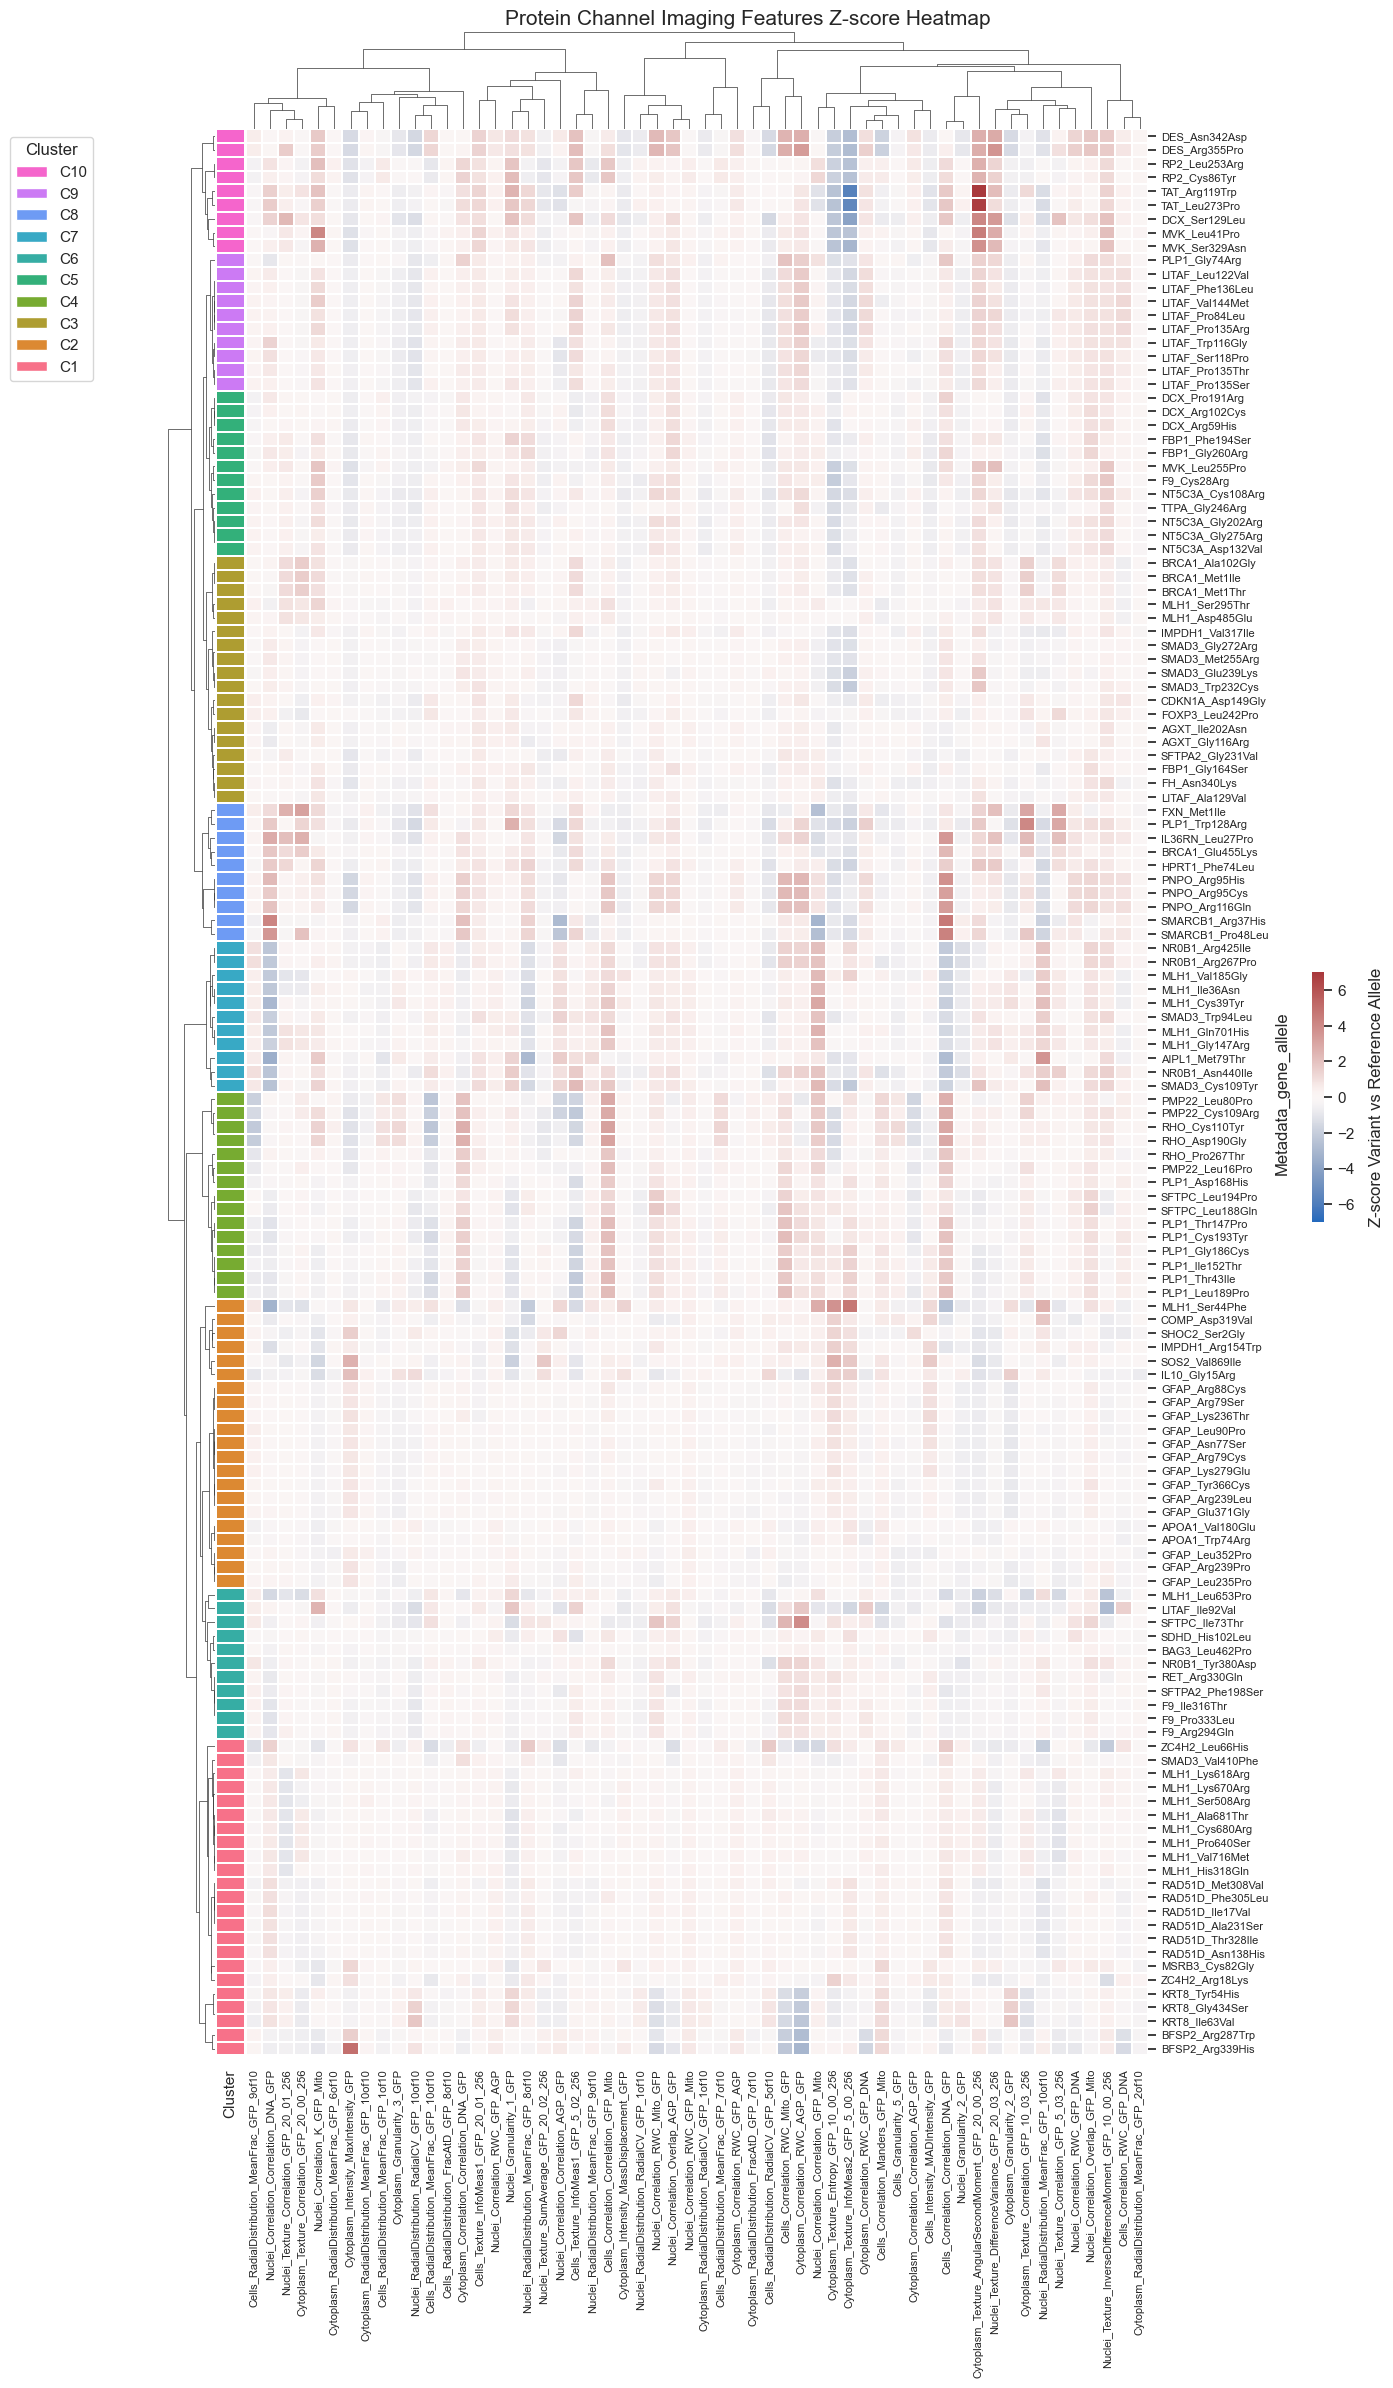

In [12]:
# ----------------------------------------------------------------------
# 4. Plot 2: Clustermap with PCA-based Dendrogram
# ----------------------------------------------------------------------
# Row colors from cluster assignment
row_colors_series = pd.Series(
    [color_map[c] for c in cluster_labels], 
    index=df.index, 
    name='Cluster'
)

# Main clustermap with correlation-based column dendrogram
g = sns.clustermap(
    data=df[col_order],  # Reorder columns to match
    cmap="vlag",
    center=0, vmin=-np.ceil(df[col_order].max().max()), 
    vmax=np.ceil(df[col_order].max().max()),
    row_colors=row_colors_series,
    row_linkage=Z,
    col_linkage=col_linkage,  # Use correlation-based linkage
    figsize=(12, 25),
    yticklabels=1,
    xticklabels=1,
    linewidths=0.05,
    cbar_pos=(.97, 0.515, 0.01, 0.1),
    dendrogram_ratio=(0.05, 0.05)
)

g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=8, rotation=90)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=8)
g.cax.set_ylabel(r"Z-score Variant vs Reference Allele", labelpad=10)
g.fig.suptitle("Protein Channel Imaging Features Z-score Heatmap", fontsize=15, y=1)

legend_handles = [Patch(facecolor=color_map[c], label=f'C{c}') 
                  for c in sorted(color_map.keys(), reverse=True)]
g.ax_heatmap.legend(
    handles=legend_handles,
    title='Cluster',
    bbox_to_anchor=(-0.27, 1.0),
    loc='upper left',
    frameon=True
)
plt.show()

In [ ]:
# # ----------------------------------------------------------------------
# # 5. Results DataFrame
# # ----------------------------------------------------------------------
# dr_res_df = df_meta.copy()
# dr_res_df["Metadata_cluster"] = cluster_labels

In [ ]:
# dr_res_df.to_csv("../../3_outputs/pheno_var_clustering_results.csv")

## 3. Explorative Analyses

In [ ]:
# pleitropy to look at for genes
## Check over-exposure 
## MLH1 PPI cross-check
## GFAP stability of the proteins

In [5]:
cluster_results_df = pl.read_csv("../../3_outputs/pheno_var_clustering_results.csv")
cluster_analysis_df = pl.read_csv("../../3_outputs/Pheno_Var_analysis_results.csv")
cluster_analysis_df

subcell_loc_df = pl.read_csv("../../1_inputs/subcell_loc/final_merged_subcellular_data.csv")
subcell_loc_df_gene = subcell_loc_df.filter(
    pl.col("HPA_Gene name").is_in(cluster_analysis_df["gene"].unique())
).unique("official_gene_name").sort("official_gene_name")
# with pl.Config(set_tbl_rows=100):
#     display(subcell_loc_df_gene)

### 3.1 Heterogeneous Cluster 4 Annotations

Mislocalization from plasma membrane to cytoplasmic enrichment

In [6]:
with pl.Config(set_tbl_rows=100):
    print(
        cluster_results_df.filter(
            pl.col("Metadata_cluster")==4
        ).sort("Metadata_gene_allele").with_columns(
            pl.col("Metadata_gene_allele").str.split('_').list.get(0).alias("official_gene_name")
        ).join(
            subcell_loc_df_gene,
            on="official_gene_name",
            how="left"
        ).select("Metadata_gene_allele","Metadata_clinvar_clnsig_clean_pp_strict")
        ## ,"official_gene_name","HPA_Main location", "HPA_Additional location", "UniProt_Subcellular location [CC]"
    )

shape: (15, 2)
┌──────────────────────┬─────────────────────────────────┐
│ Metadata_gene_allele ┆ Metadata_clinvar_clnsig_clean_… │
│ ---                  ┆ ---                             │
│ str                  ┆ str                             │
╞══════════════════════╪═════════════════════════════════╡
│ PLP1_Asp168His       ┆ Pathogenic                      │
│ PLP1_Cys193Tyr       ┆ Likely pathogenic               │
│ PLP1_Gly186Cys       ┆ Pathogenic                      │
│ PLP1_Ile152Thr       ┆ Likely pathogenic               │
│ PLP1_Leu189Pro       ┆ VUS                             │
│ PLP1_Thr147Pro       ┆ Pathogenic                      │
│ PLP1_Thr43Ile        ┆ Likely pathogenic               │
│ PMP22_Cys109Arg      ┆ VUS                             │
│ PMP22_Leu16Pro       ┆ Pathogenic                      │
│ PMP22_Leu80Pro       ┆ VUS                             │
│ RHO_Asp190Gly        ┆ Likely pathogenic               │
│ RHO_Cys110Tyr        ┆ Pathogenic      

### 3.2 Gene-dominant cluster

### 3.2.1 LITAF

#### 3.2.1 GFAP

Lacoste et al: GFAP variant localization ranged from reference-like in- termediate filament localization to diffuse cytoplasmic staining to prominent cytoplasmic punctae, likely reflecting pathogenic aggregation66
(Figure 5B). The localization pattern correlated with the age of onset of the disease: the E207Q variant associ- ated with adult-onset disease showed only a partial diffuse local- ization, whereas the R258P variant with the youngest age of onset was localized to distinct punctae.

In [13]:
# cluster_analysis_df.filter(
#     pl.col("gene")=="GFAP"
# )

with pl.Config(set_tbl_rows=100):
    print(
        cluster_analysis_df.filter(
            pl.col("cluster")==2
        )
    )

# with pl.Config(set_tbl_rows=100):
#     print(
#         cluster_results_df.filter(
#             pl.col("Metadata_cluster")==2
#         ).select("Metadata_gene_allele","Metadata_clinvar_clnsig_clean_pp_strict")
#     )

shape: (21, 9)
┌─────────────┬────────┬─────────┬─────────────┬───┬─────────────┬─────────────┬──────────┬────────┐
│ gene_allele ┆ gene   ┆ cluster ┆ primary_dis ┆ … ┆ cleaned_dis ┆ disease_cou ┆ score    ┆ is_hit │
│ ---         ┆ ---    ┆ ---     ┆ ease_module ┆   ┆ eases       ┆ nt          ┆ ---      ┆ ---    │
│ str         ┆ str    ┆ i64     ┆ ---         ┆   ┆ ---         ┆ ---         ┆ f64      ┆ bool   │
│             ┆        ┆         ┆ str         ┆   ┆ str         ┆ i64         ┆          ┆        │
╞═════════════╪════════╪═════════╪═════════════╪═══╪═════════════╪═════════════╪══════════╪════════╡
│ APOA1_Val18 ┆ APOA1  ┆ 2       ┆ Other_Genet ┆ … ┆ HYPOALPHALI ┆ 1           ┆ 0.841595 ┆ true   │
│ 0Glu        ┆        ┆         ┆ ic_Disorder ┆   ┆ POPROTEINEM ┆             ┆          ┆        │
│             ┆        ┆         ┆ s           ┆   ┆ IA, PRIM…   ┆             ┆          ┆        │
│ GFAP_Arg239 ┆ GFAP   ┆ 2       ┆ Other_Genet ┆ … ┆ ALEXANDER   ┆ 1        

In [12]:
# fig, axes = plt.subplots(1,2,figsize=(10,6),sharey=True)
# df_plot = pl.DataFrame(dr_res_df.reset_index()).with_columns(
#     (pl.col("Metadata_g2p_Signal (UniProt)")=="Signal").alias("Signal_Peptide"),
#     (pl.col("Metadata_g2p_Transit peptide (UniProt)")=="Mitochondrion").alias("Transit_Peptide"),
#     pl.col("Metadata_gene_allele").alias("gene_variant")    
# ).sort("Metadata_cluster")

# plot_assay_hit_by_category_perc(
#     df_plot, 
#     "Signal_Peptide", "Metadata_cluster", 
#     f"Functional Hit Rate by Any Assay",
#     ax=axes[0]
# )
# plot_assay_hit_by_category_perc(
#     df_plot, 
#     "Transit_Peptide", "Metadata_cluster", 
#     f"Functional Hit Rate by Any Assay",
#     ax=axes[1]
# )
# plt.subplots_adjust(wspace=0.1)
# plt.show()